# Figure 4

Panel a is a schematic. This notebook draws panels b–f from the source data.

Data: `Wilhelm_SourceData.xlsx` (one worksheet per panel) and the `Wilhelm_SourceData_*.parquet` / `*.csv` files of the figshare deposit (column descriptions in the deposit's `README.md`). Set `FIGSHARE_ARTICLE_ID` in the next cell (or as environment variable; while the article is private also `FIGSHARE_TOKEN`) to download the files into `./data`, or set `SOURCE_DATA_DIR` to a local copy of the deposit.


Curves in panels b–d are drawn as smoothing splines (`scipy.interpolate.UnivariateSpline`) through the deposited unsmoothed points (ties in x collapsed to the last point, 200 evaluation points). The smoothing factor is chosen per curve as the largest value of `SMOOTHS` for which the spline keeps the monotonicity of the data; if none does, a monotone PCHIP interpolation through ~40 evenly spaced points is used.

In [1]:
import source_data as sd
from source_data import fetch, readme, table

# figshare article with the source data (https://doi.org/10.6084/m9.figshare.34601982); alternatively set the environment variable
# FIGSHARE_ARTICLE_ID, or SOURCE_DATA_DIR to a local copy of the files. While the article is private, set FIGSHARE_TOKEN.
sd.FIGSHARE_ARTICLE_ID = sd.FIGSHARE_ARTICLE_ID or ""

In [2]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.patches import Ellipse
from scipy.interpolate import UnivariateSpline, PchipInterpolator

plt.rcParams['pdf.fonttype'] = 42
DATA = Path('data')
DATA.mkdir(exist_ok=True)
FIG_DIR = Path('regenerated_panels') / 'Fig4'
FIG_DIR.mkdir(parents=True, exist_ok=True)
COLORS = {'Prosit-22PTM': '#e1822b', 'MSFragger': 'royalblue', 'DeepFLR': 'limegreen'}
SMOOTHS = (0.05, 0.02, 0.01, 0.005, 0.002, 0.001, 5e-4, 2e-4, 1e-4)  # tried per curve, largest first


def fit_curve(x, y, n=200, monotone=None):
    """Smoothing spline y(x) through the curve points (ties in x collapsed to the last point).
    The smoothing factor is chosen per curve: the largest value in SMOOTHS for which the smoothed curve keeps the
    monotonicity of the data (monotone='increasing' or 'decreasing'), so that no loops appear."""
    d = pd.DataFrame({'x': x, 'y': y}).groupby('x', sort=True)['y'].last()
    xv, yv = d.index.values.astype(float), d.values
    xs = np.linspace(xv.min(), xv.max(), n)
    for s in SMOOTHS:
        ys = UnivariateSpline(xv, yv, s=s)(xs)
        dy = np.diff(ys)
        if monotone is None or (monotone == 'increasing' and (dy >= -1e-9).all()) or \
                (monotone == 'decreasing' and (dy <= 1e-9).all()):
            return xs, ys
    # fallback: monotone PCHIP through the running extreme of ~40 evenly spaced points (no loops)
    idx = np.unique(np.linspace(0, len(xv) - 1, 40).astype(int))
    yk = np.maximum.accumulate(yv[idx]) if monotone == 'increasing' else np.minimum.accumulate(yv[idx])
    return xs, PchipInterpolator(xv[idx], yk)(xs)


readme('Fig4')

,Figure,Panel,Worksheet,figshare file(s),Content,Tables in worksheet (top to bottom)
0,Fig. 4,b,NaN,Wilhelm_SourceData_Fig4b.parquet; Wilhelm_Sour...,Cumulative number of correctly localised PSMs ...,NaN
1,Fig. 4,c,NaN,Wilhelm_SourceData_Fig4c.parquet; Wilhelm_Sour...,"Precision-recall of phosphosite localisation, ...",NaN
2,Fig. 4,d,NaN,Wilhelm_SourceData_Fig4d.parquet; Wilhelm_Sour...,"Precision-recall of phosphosite localisation, ...",NaN
3,Fig. 4,e,Fig4e,NaN,Number of pHis sites per Venn region (exclusiv...,Fig4e; Fig4e_totals
4,Fig. 4,f,Fig4f,NaN,pHis sites as percentage of pS + pT + pY sites...,Fig4f


## Panel b — phospho localisation vs state of the art

Cumulative number of correctly localised PSMs vs false localisation rate (FLR), synthetic phosphopeptide library (PXD007058), Orbitrap HCD; solid = all sites, dashed = adjacent sites. Vertical lines at FLR 0.01 and 0.05.

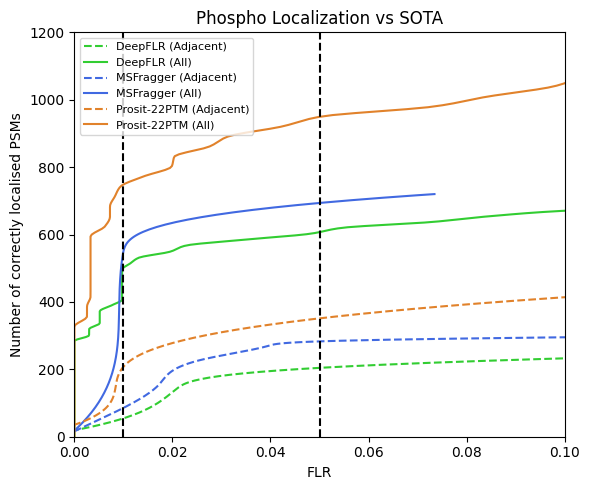

,tool,site_context,FLR<=0.01,FLR<=0.05
0,DeepFLR,Adjacent,57,205
1,DeepFLR,All,514,605
2,MSFragger,Adjacent,100,287
3,MSFragger,All,437,698
4,Prosit-22PTM,Adjacent,209,364
5,Prosit-22PTM,All,747,950


In [3]:
b = pd.read_parquet(fetch('Wilhelm_SourceData_Fig4b.parquet'))
fig, ax = plt.subplots(figsize=(6, 5))
for (tool, ctx), g in b.groupby(['tool', 'site_context']):
    n_smooth, flr_smooth = fit_curve(g['n_correct_PSMs'], g['FLR'], monotone='increasing')
    ax.plot(flr_smooth, n_smooth, color=COLORS[tool], ls='-' if ctx == 'All' else '--',
            label=f'{tool} ({ctx})')
for x in (0.01, 0.05):
    ax.axvline(x, color='k', ls='--')
ax.set_xlim(0, 0.1)
ax.set_ylim(0, 1200)
ax.set_xlabel('FLR')
ax.set_ylabel('Number of correctly localised PSMs')
ax.set_title('Phospho Localization vs SOTA')
ax.legend(loc='upper left', fontsize=8)
plt.tight_layout()
for ext in ('pdf', 'png'):
    plt.savefig(FIG_DIR / f'Fig4b.{ext}', dpi=300, bbox_inches='tight')
plt.show()
table('Fig4b_summary')

## Panel c — phospho localisation on ITMS

Precision-recall of phosphosite localisation on ion-trap CID (ITMS) scans of the ProteomeTools phospho permutation pools; solid = non-adjacent, dashed = adjacent sites. Horizontal lines at precision 0.99 and 0.95.

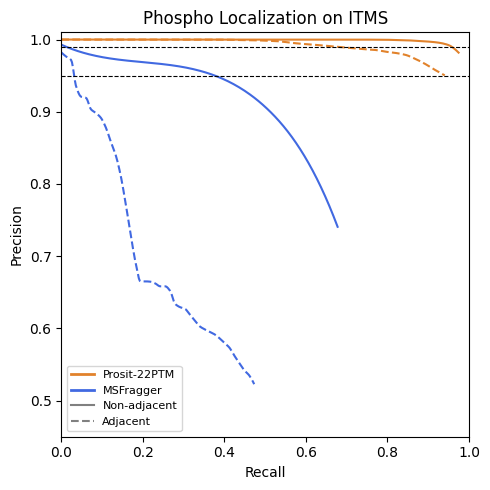

,tool,site_context,n_PSMs,n_correct,final_precision,final_recall,n_union_identified (recall denominator),recall_at_precision>=0.99,recall_at_precision>=0.95
0,Prosit-22PTM,Non adjacent,38383,37688,0.981893,0.974480,38675,0.958888,0.974480
1,MSFragger,Non adjacent,35548,26212,0.737369,0.677750,38675,0.001034,0.383219
2,Prosit-22PTM,Adjacent,20636,19613,0.950426,0.940491,20854,0.671574,0.940491
3,MSFragger,Adjacent,18875,9867,0.522755,0.473147,20854,0.000048,0.029203


In [4]:
def pr_plot(df, title, ylim):
    from matplotlib.lines import Line2D
    fig, ax = plt.subplots(figsize=(5, 5))
    for (tool, ctx), g in df.groupby(['tool', 'site_context']):
        recall_smooth, precision_smooth = fit_curve(g['recall'], g['precision'], monotone='decreasing')
        ax.plot(recall_smooth, precision_smooth, color=COLORS[tool], ls='-' if ctx == 'Non adjacent' else '--')
    for y in (0.99, 0.95):
        ax.axhline(y, color='k', ls='--', lw=0.8)
    ax.set_xlim(0, 1)
    ax.set_ylim(*ylim)
    ax.set_xlabel('Recall')
    ax.set_ylabel('Precision')
    ax.set_title(title)
    tools = [t for t in COLORS if t in set(df['tool'])]
    handles = [Line2D([], [], color=COLORS[t], lw=2) for t in tools] + \
              [Line2D([], [], color='grey', ls='-'), Line2D([], [], color='grey', ls='--')]
    ax.legend(handles, tools + ['Non-adjacent', 'Adjacent'], loc='lower left', fontsize=8)
    plt.tight_layout()


pr_plot(pd.read_parquet(fetch('Wilhelm_SourceData_Fig4c.parquet')), 'Phospho Localization on ITMS', (0.45, 1.01))
for ext in ('pdf', 'png'):
    plt.savefig(FIG_DIR / f'Fig4c.{ext}', dpi=300, bbox_inches='tight')
plt.show()
table('Fig4c_summary')

## Panel d — phospho localisation on FTMS

Precision-recall of phosphosite localisation on Orbitrap HCD (FTMS) scans of the ProteomeTools phospho permutation pools; solid = non-adjacent, dashed = adjacent sites. Horizontal lines at precision 0.99 and 0.95.

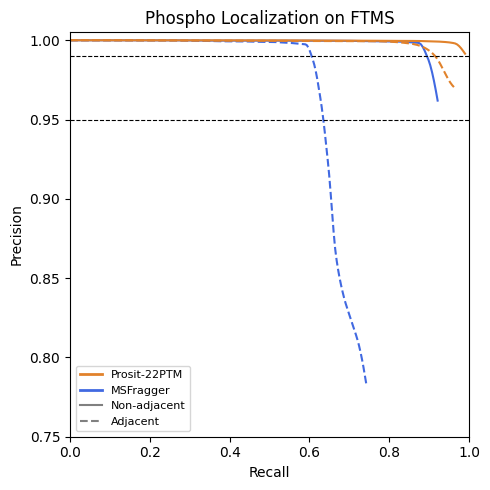

,tool,site_context,n_PSMs,n_correct,final_precision,final_recall,n_union_identified (recall denominator),recall_at_precision>=0.99,recall_at_precision>=0.95
0,Prosit-22PTM,Non adjacent,96859,96039,0.991534,0.990083,97001,0.990083,0.990083
1,MSFragger,Non adjacent,92912,89376,0.961942,0.921393,97001,0.896011,0.921393
2,Prosit-22PTM,Adjacent,49269,47697,0.968094,0.967269,49311,0.915556,0.967269
3,MSFragger,Adjacent,46802,36633,0.782723,0.742897,49311,0.608120,0.635862


In [5]:
pr_plot(pd.read_parquet(fetch('Wilhelm_SourceData_Fig4d.parquet')), 'Phospho Localization on FTMS', (0.75, 1.005))
for ext in ('pdf', 'png'):
    plt.savefig(FIG_DIR / f'Fig4d.{ext}', dpi=300, bbox_inches='tight')
plt.show()
table('Fig4d_summary')

## Panel e — pHis sites (Venn diagrams)

Number of pHis sites per Venn region (exclusive; table `Fig4e`) and total pHis sites per set (outer labels; table `Fig4e_totals`), E. coli and HEK293.

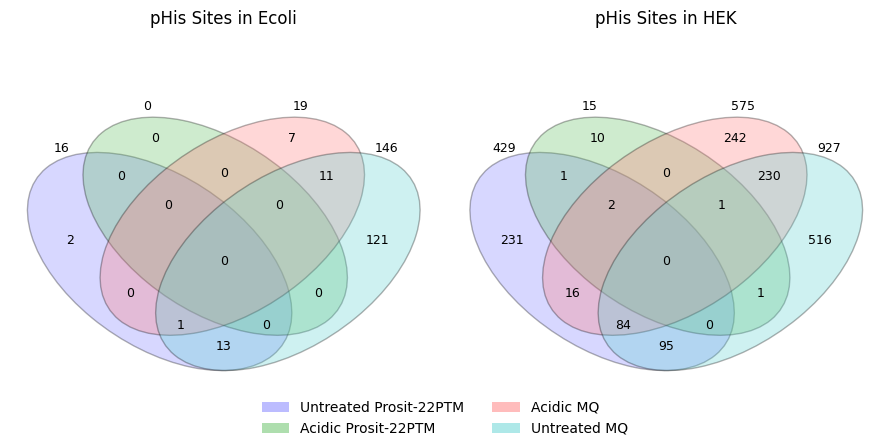

In [6]:
e = table('Fig4e')
tot = table('Fig4e_totals')
SETS = ['Untreated Prosit-22PTM', 'Acidic Prosit-22PTM', 'Acidic MQ', 'Untreated MQ']
COL = ['#7b7bff', '#5fbf5f', '#ff7b7b', '#5fd3d3']
XE, YE, AE = [35, 48, 52, 65], [35, 45, 45, 35], [225, 225, 315, 315]
XT = [12, 32, 68, 88, 14, 34, 66, 86, 26, 28, 50, 50, 72, 74, 37, 60, 40, 63, 50]
YT = [67, 79, 79, 67, 41, 70, 70, 41, 59, 26, 11, 60, 26, 59, 51, 17, 17, 51, 35]
from itertools import combinations
REGIONS = [' & '.join(SETS[i] for i in c) for r in range(1, 5) for c in combinations(range(4), r)]

fig, axes = plt.subplots(1, 2, figsize=(9, 4.5))
for ax, sample, title in zip(axes, ['E. coli', 'HEK293'], ['pHis Sites in Ecoli', 'pHis Sites in HEK']):
    ax.set_xlim(0, 100)
    ax.set_ylim(0, 100)
    ax.axis('off')
    for i in range(4):
        ax.add_artist(Ellipse((XE[i], YE[i]), 45, 75, angle=AE[i], fc=COL[i], alpha=.3, ec='k'))
    t = tot[tot['sample'] == sample].set_index('set')['n_pHis_sites_total']
    r = e[e['sample'] == sample].set_index('region (exclusively in)')['n_pHis_sites']
    for j, v in enumerate([t[s] for s in SETS] + [r[k] for k in REGIONS]):
        ax.text(XT[j], YT[j], v, ha='center', va='center', fontsize=9)
    ax.set_title(title)
fig.legend([plt.Rectangle((0, 0), 1, 1, fc=c, alpha=.5) for c in COL], SETS, loc='lower center', ncol=2, frameon=False)
plt.tight_layout(rect=(0, 0.1, 1, 1))
for ext in ('pdf', 'png'):
    plt.savefig(FIG_DIR / f'Fig4e.{ext}', dpi=300, bbox_inches='tight')
plt.show()

## Panel f — ratio of pHis to pSTY sites

pHis sites as percentage of pS + pT + pY sites per sample and tool.

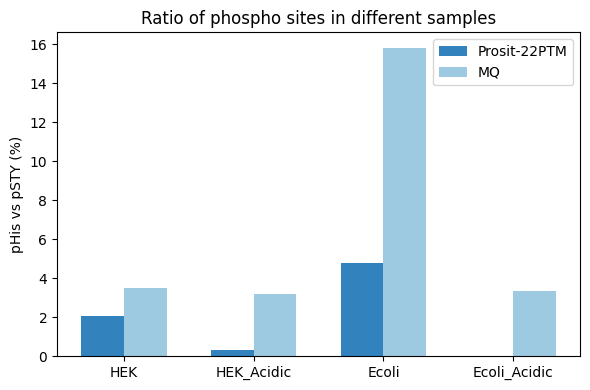

,sample,tool,n_pH_sites,n_pS_sites,n_pT_sites,n_pY_sites,pH_vs_pSTY (%)
0,Ecoli,Prosit-22PTM,16,447,100,62,4.76
1,Ecoli,MQ,146,575,275,73,15.82
2,Ecoli_Acidic,Prosit-22PTM,0,340,50,56,0.00
3,Ecoli_Acidic,MQ,19,361,168,41,3.33
4,HEK,Prosit-22PTM,429,22553,3705,416,2.04
5,HEK,MQ,927,22523,3872,298,3.47
6,HEK_Acidic,Prosit-22PTM,15,7844,862,39,0.32
7,HEK_Acidic,MQ,575,15480,2303,111,3.21


In [7]:
f = table('Fig4f')
order = ['HEK', 'HEK_Acidic', 'Ecoli', 'Ecoli_Acidic']
pt = f.pivot(index='sample', columns='tool', values='pH_vs_pSTY (%)').loc[order]
x = np.arange(len(order))
fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(x - 0.165, pt['Prosit-22PTM'], 0.33, color='#3182bd', label='Prosit-22PTM')
ax.bar(x + 0.165, pt['MQ'], 0.33, color='#9ecae1', label='MQ')
ax.set_xticks(x, order)
ax.set_ylabel('pHis vs pSTY (%)')
ax.set_title('Ratio of phospho sites in different samples')
ax.legend()
plt.tight_layout()
for ext in ('pdf', 'png'):
    plt.savefig(FIG_DIR / f'Fig4f.{ext}', dpi=300, bbox_inches='tight')
plt.show()
f